In [1]:
%matplotlib inline
import numpy as np
import cv2
import matplotlib.pyplot as plt

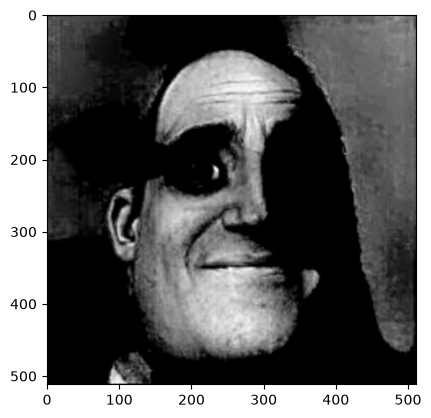

In [2]:
image_bgr = cv2.imread('img.jpg')
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
gray = cv2.resize(gray, (512, 512), interpolation=cv2.INTER_AREA)
plt.imshow(gray, cmap="gray")

In [3]:
# одна ступень 2D-преобразования Хаара
def haar_2d(img):
    img = img.astype(np.float32)
    h, w = img.shape
    assert h % 2 == 0 and w % 2 == 0, "размеры должны быть чётными"

    a, b = img[0::2, :], img[1::2, :]
    L, H = (a + b) * 0.5, (a - b) * 0.5
    rows = np.vstack([L, H])

    L_rows, H_rows = rows[:h // 2, :], rows[h // 2:, :]
    a, b = L_rows[:, 0::2], L_rows[:, 1::2]
    LL, LH = (a + b) * 0.5, (a - b) * 0.5
    a, b = H_rows[:, 0::2], H_rows[:, 1::2]
    HL, HH = (a + b) * 0.5, (a - b) * 0.5

    out = np.zeros((h, w), dtype=np.float32)
    out[: h // 2, : w // 2] = LL
    out[: h // 2, w // 2:]  = LH
    out[h // 2:, : w // 2]  = HL
    out[h // 2:, w // 2:]   = HH
    return out, LL, LH, HL, HH


In [4]:
# три ступени
current = gray.copy()
LL_levels = []
details = []
full_outs = []

for lvl in range(3):
    out, LL, LH, HL, HH = haar_2d(current)
    LL_levels.append(LL)
    details.append((LH, HL, HH))
    full_outs.append(out)
    current = LL

In [5]:
# Печать размеров и диапазонов
for i, ((LH, HL, HH), LL) in enumerate(zip(details, LL_levels), 1):
    print(f"Ступень {i}:")
    print(f"  LL{i}: shape={LL.shape},  min={LL.min():7.1f}, max={LL.max():7.1f}")
    print(f"  LH{i}: shape={LH.shape}, min={LH.min():7.1f}, max={LH.max():7.1f}")
    print(f"  HL{i}: shape={HL.shape}, min={HL.min():7.1f}, max={HL.max():7.1f}")
    print(f"  HH{i}: shape={HH.shape}, min={HH.min():7.1f}, max={HH.max():7.1f}")

Ступень 1:
  LL1: shape=(256, 256),  min=    0.0, max=  246.8
  LH1: shape=(256, 256), min=  -47.2, max=   35.2
  HL1: shape=(256, 256), min=  -43.2, max=   64.8
  HH1: shape=(256, 256), min=   -8.0, max=    9.2
Ступень 2:
  LL2: shape=(128, 128),  min=    0.0, max=  243.2
  LH2: shape=(128, 128), min=  -53.7, max=   64.1
  HL2: shape=(128, 128), min=  -60.2, max=   48.4
  HH2: shape=(128, 128), min=  -13.2, max=   18.5
Ступень 3:
  LL3: shape=(64, 64),  min=    0.0, max=  238.6
  LH3: shape=(64, 64), min=  -67.9, max=   56.8
  HL3: shape=(64, 64), min=  -62.8, max=   48.0
  HH3: shape=(64, 64), min=  -23.5, max=   23.2


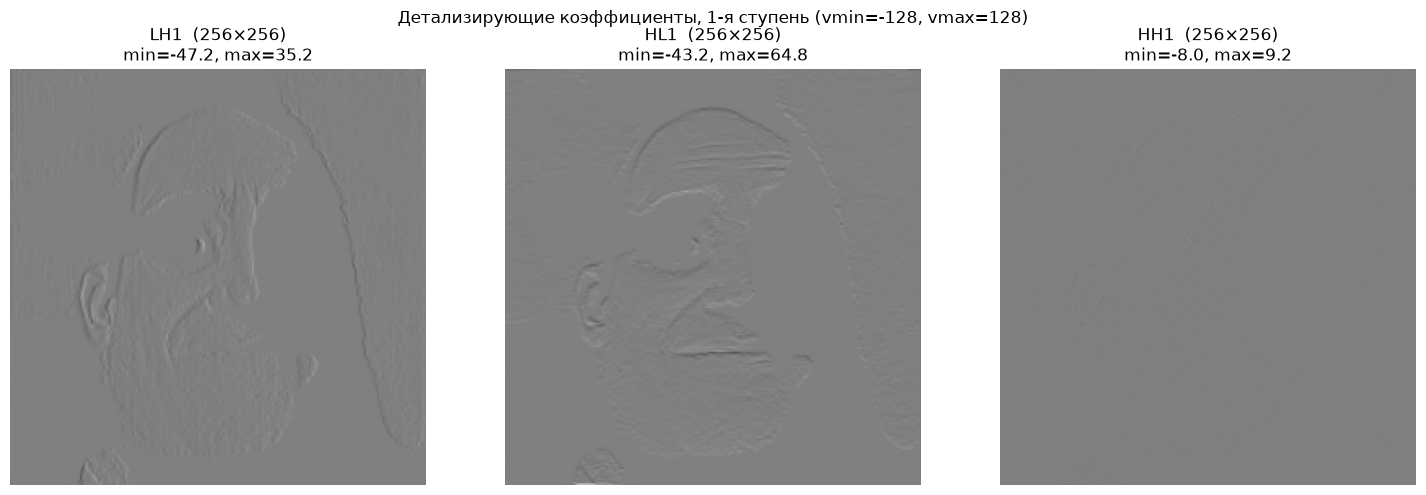

In [6]:
# Визуализация детализирующих коэффициентов 1-й ступени
LH1, HL1, HH1 = details[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, band, name in zip(axes, [LH1, HL1, HH1], ['LH1', 'HL1', 'HH1']):
    ax.imshow(band, cmap='gray', vmin=-128, vmax=128)
    ax.set_title(f'{name}  ({band.shape[0]}×{band.shape[1]})\n'
                 f'min={band.min():.1f}, max={band.max():.1f}')
    ax.axis('off')
plt.suptitle('Детализирующие коэффициенты, 1-я ступень (vmin=-128, vmax=128)')
plt.tight_layout()
plt.show()

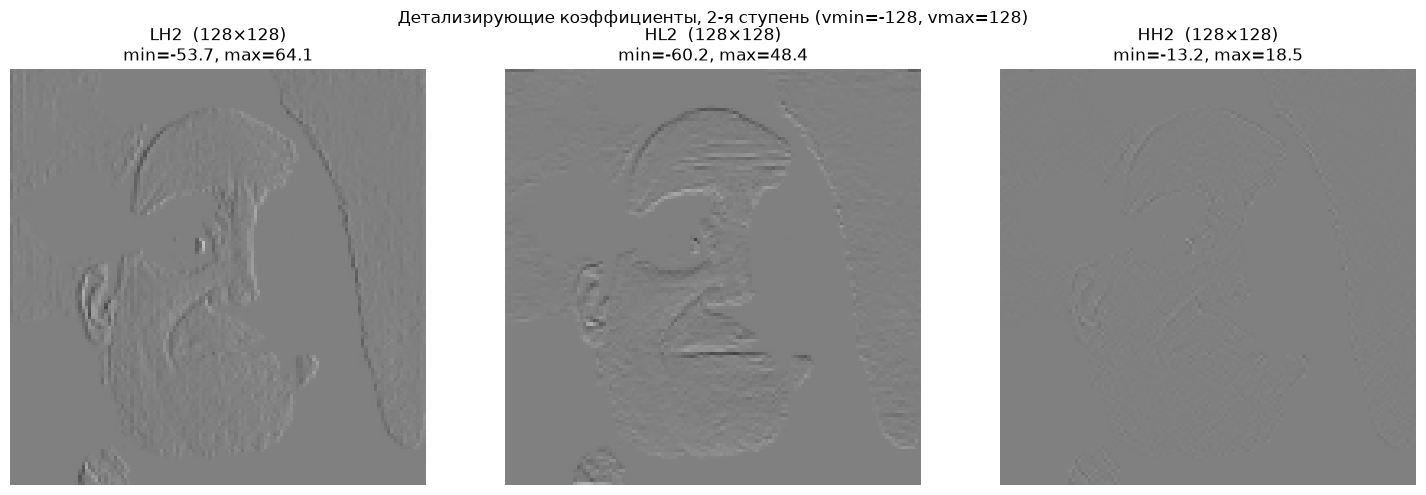

In [7]:
# Визуализация детализирующих коэффициентов 2-й ступени
LH2, HL2, HH2 = details[1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, band, name in zip(axes, [LH2, HL2, HH2], ['LH2', 'HL2', 'HH2']):
    ax.imshow(band, cmap='gray', vmin=-128, vmax=128)
    ax.set_title(f'{name}  ({band.shape[0]}×{band.shape[1]})\n'
                 f'min={band.min():.1f}, max={band.max():.1f}')
    ax.axis('off')
plt.suptitle('Детализирующие коэффициенты, 2-я ступень (vmin=-128, vmax=128)')
plt.tight_layout()
plt.show()

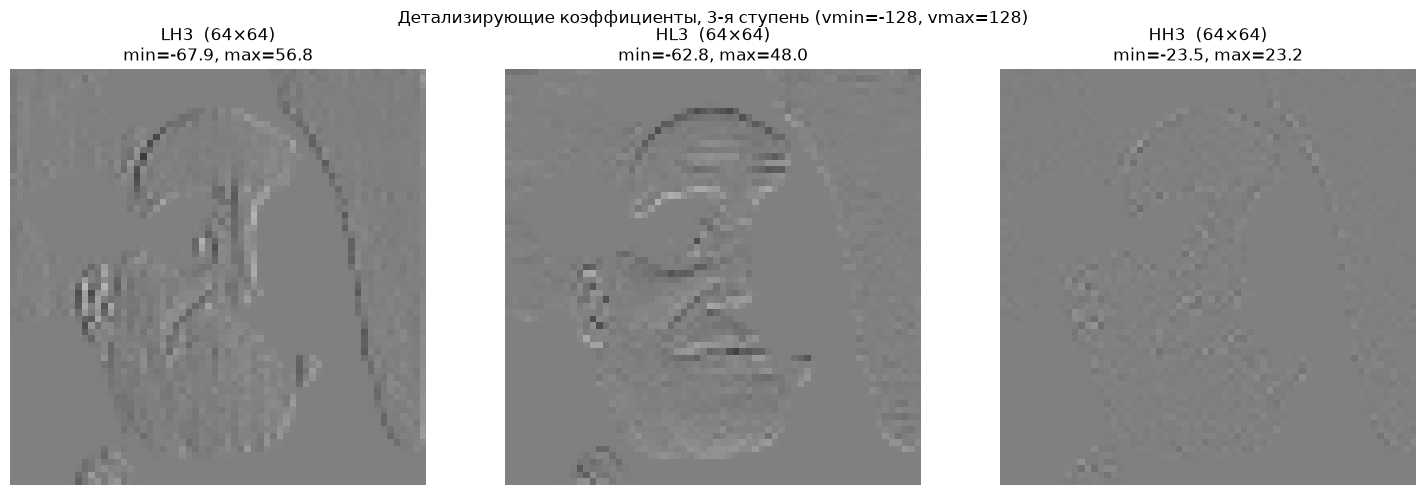

In [8]:
# Визуализация детализирующих коэффициентов 3-й ступени
LH3, HL3, HH3 = details[2]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, band, name in zip(axes, [LH3, HL3, HH3], ['LH3', 'HL3', 'HH3']):
    ax.imshow(band, cmap='gray', vmin=-128, vmax=128)
    ax.set_title(f'{name}  ({band.shape[0]}×{band.shape[1]})\n'
                 f'min={band.min():.1f}, max={band.max():.1f}')
    ax.axis('off')
plt.suptitle('Детализирующие коэффициенты, 3-я ступень (vmin=-128, vmax=128)')
plt.tight_layout()
plt.show()

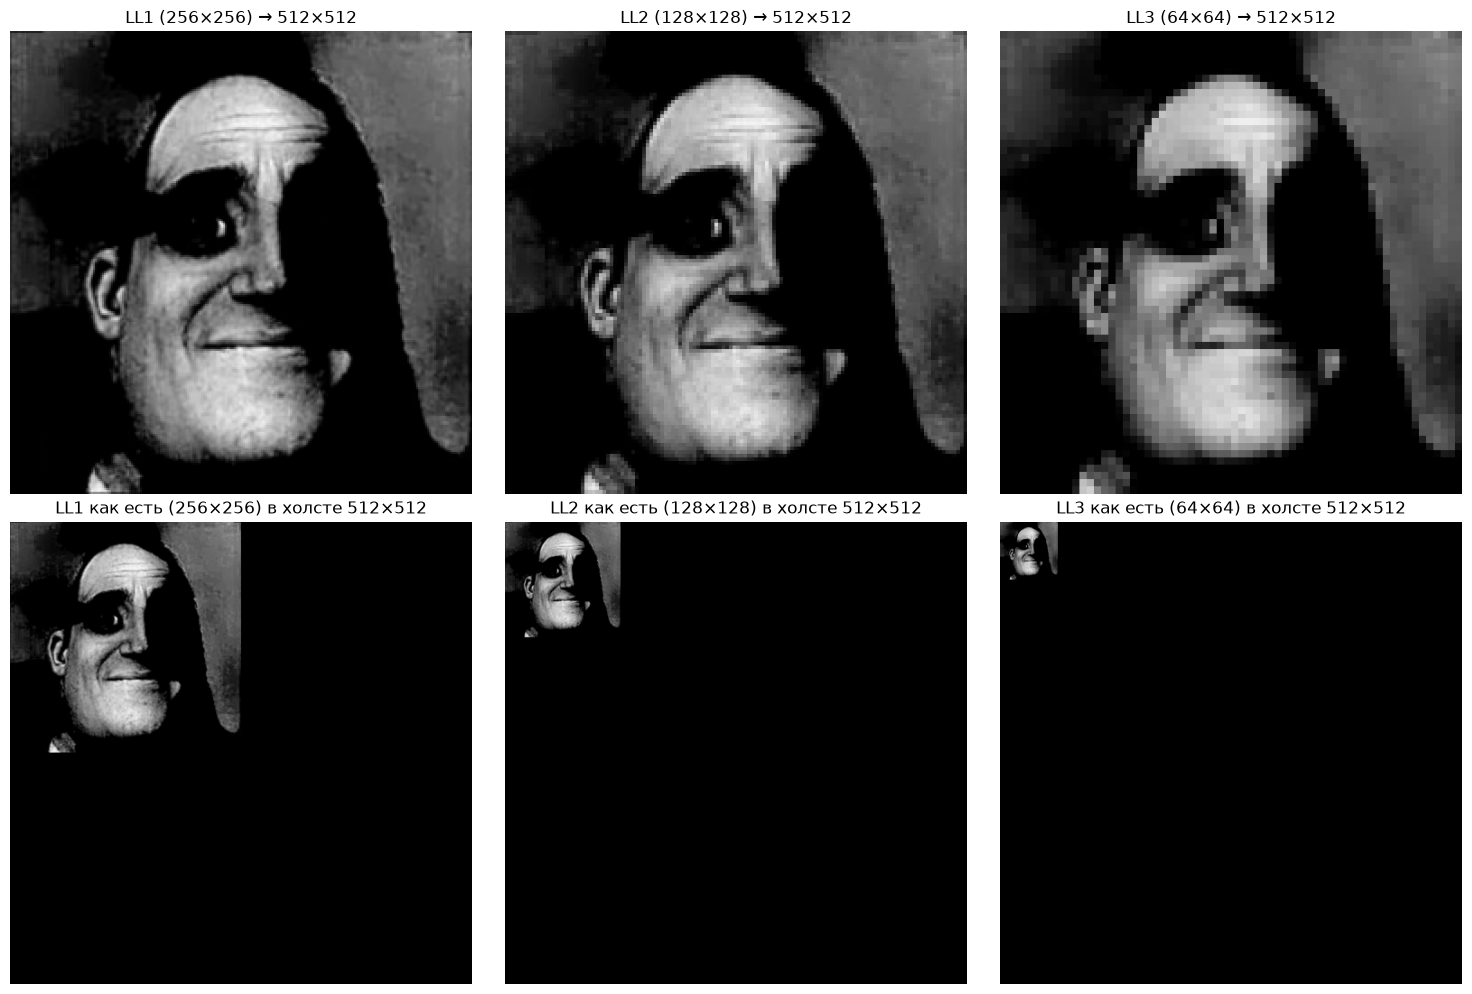

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ll in enumerate(LL_levels):
    big = cv2.resize(ll, (512, 512), interpolation=cv2.INTER_NEAREST)
    axes[0, i].imshow(big, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(f'LL{i+1} ({ll.shape[0]}×{ll.shape[1]}) → 512×512')
    axes[0, i].axis('off')

for i, ll in enumerate(LL_levels):
    canvas = np.zeros((512, 512), dtype=np.float32)
    h, w = ll.shape
    canvas[:h, :w] = ll
    axes[1, i].imshow(canvas, cmap='gray', vmin=0, vmax=255)
    axes[1, i].set_title(f'LL{i+1} как есть ({h}×{w}) в холсте 512×512')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()